# Chương 4 – Các hệ màu và kỹ thuật in ảnh
## Bài tập thực hành

Mục tiêu:
- Thực hành **mô hình màu RGB** (tách kênh màu, chuyển ảnh xám).
- Cài đặt các phép **chuyển đổi hệ màu**: RGB ↔ CMY, RGB → CMYK, RGB → HSV.
- Quan sát **ảnh hưởng của điều kiện chiếu sáng** lên các kênh màu và ứng dụng **phát hiện da người** bằng ngưỡng trên không gian màu HSV/YCrCb.
- Thực hành các **kỹ thuật in ảnh**: tách ngưỡng, **khuếch tán lỗi** (một chiều, Floyd–Steinberg) và **nửa cường độ (halftone)** bằng ma trận ngưỡng.
- Tổng hợp: mô phỏng quy trình in ảnh màu bằng 4 bản mực C, M, Y, K.

Các ô code có dấu `#### YOUR CODE HERE ####` là phần bạn cần hoàn thành. Hàm `check(...)` ở các ô kiểm tra sẽ báo kết quả đúng/sai so với đáp án bài tập tính tay.

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

%matplotlib inline

IMG_DIR = 'images'

def check(name, cond):
    """In kết quả kiểm tra: cond là biểu thức hoặc hàm không tham số trả về True/False."""
    try:
        ok = bool(cond() if callable(cond) else cond)
    except Exception:
        ok = False
    print(('✔ Đúng: ' if ok else '✘ Chưa đúng: ') + name)

def show(images, titles, cmap=None, figsize=None):
    n = len(images)
    plt.figure(figsize=figsize or (5 * n, 5))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, i + 1)
        plt.imshow(im, cmap=cmap)
        plt.title(t)
        plt.axis('off')
    plt.show()

## 1. Mô hình màu RGB

Ảnh màu RGB là mảng 3 chiều `(cao, rộng, 3)`. OpenCV đọc ảnh theo thứ tự kênh **B, G, R** còn `matplotlib` hiển thị theo thứ tự **R, G, B**, vì vậy cần đổi bằng `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`.

### 1.1. Tách các kênh màu

**Yêu cầu**: viết hàm `split_channels(img)` nhận ảnh RGB, trả về 3 ảnh màu `R_img`, `G_img`, `B_img`; mỗi ảnh chỉ giữ lại một kênh tương ứng, hai kênh còn lại gán bằng 0 (phối màu cộng: chỉ còn một nguồn sáng).

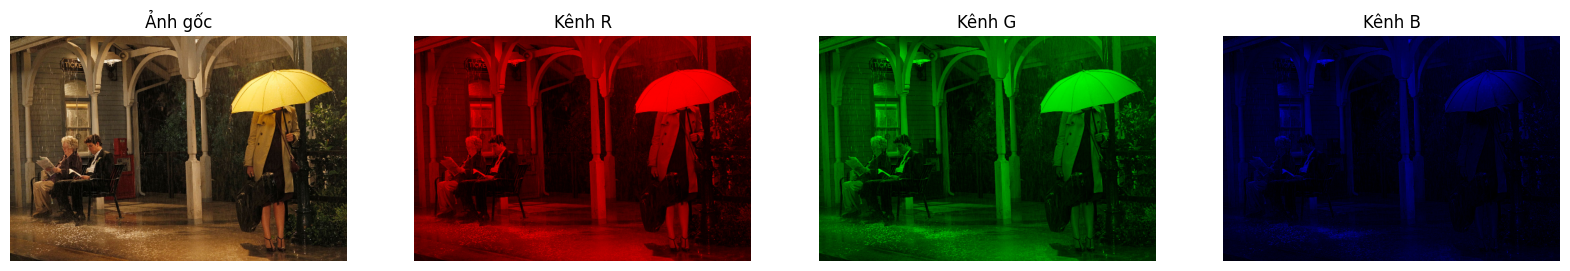

In [2]:
img = cv2.cvtColor(cv2.imread(os.path.join(IMG_DIR, 'himym.jpg')), cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (600, 400))

def split_channels(img):
    R_img, G_img, B_img = [np.zeros_like(img) for _ in range(3)]
    R_img[..., 0] = img[..., 0]
    G_img[..., 1] = img[..., 1]
    B_img[..., 2] = img[..., 2]
    return R_img, G_img, B_img

R_img, G_img, B_img = split_channels(img)
show([img, R_img, G_img, B_img], ['Ảnh gốc', 'Kênh R', 'Kênh G', 'Kênh B'], figsize=(20, 4))

**Nhận xét**: Mỗi ảnh đầu ra chỉ có một kênh màu khác 0, vì vậy cảnh vẫn giữ bố cục nhưng mang sắc đỏ, xanh lá hoặc xanh lam. Các chi tiết ở kênh B tối hơn đáng kể. Đây là đặc điểm phù hợp với ảnh gốc có nhiều vùng vàng và nâu, nơi thành phần R và G thường nổi bật hơn B.

### 1.2. Chuyển ảnh màu sang ảnh xám

Công thức độ sáng (chuẩn ITU-R BT.601): `Y = 0.299·R + 0.587·G + 0.114·B`.

**Yêu cầu**: viết hàm `rgb_to_gray(img)` theo công thức trên (không dùng `cv2.cvtColor`), kết quả làm tròn và đưa về `uint8`. So sánh với `cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)`.

Sai khác lớn nhất so với OpenCV: 1
✔ Đúng: rgb_to_gray khớp OpenCV (sai khác ≤ 1)


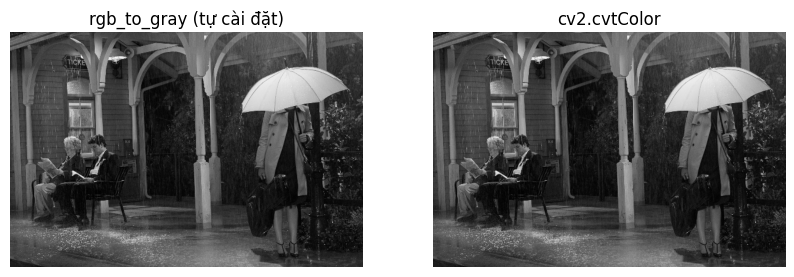

In [3]:
def rgb_to_gray(img):
    gray = img.astype(float) @ np.array([0.299, 0.587, 0.114])
    return np.uint8(np.round(gray))

gray_mine = rgb_to_gray(img)
gray_cv = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print('Sai khác lớn nhất so với OpenCV:', np.abs(gray_mine.astype(int) - gray_cv.astype(int)).max())
check('rgb_to_gray khớp OpenCV (sai khác ≤ 1)', lambda: np.abs(gray_mine.astype(int) - gray_cv.astype(int)).max() <= 1)
show([gray_mine, gray_cv], ['rgb_to_gray (tự cài đặt)', 'cv2.cvtColor'], cmap='gray')

**Nhận xét**: Công thức có trọng số tạo ảnh xám giữ được độ tương phản giữa chiếc ô, người và nền. So với OpenCV, sai khác lớn nhất là 1 mức trên thang 0–255, nên hai ảnh nhìn gần như không khác nhau. Chênh lệch nhỏ phù hợp với khác biệt về cách tính và làm tròn.

## 2. Hệ màu CMY và CMYK

CMY là hệ **màu trừ** dùng trong in ấn. Với R, G, B, C, M, Y ∈ [0, 1]:

$$\begin{bmatrix}C\\M\\Y\end{bmatrix}=\begin{bmatrix}1\\1\\1\end{bmatrix}-\begin{bmatrix}R\\G\\B\end{bmatrix}$$

### 2.1. Chuyển RGB → CMY

**Yêu cầu**: viết hàm `rgb_to_cmy(rgb)` nhận mảng uint8 có kích thước `(..., 3)` (giá trị 0–255) và trả về mảng số thực CMY trong [0, 1]. Kiểm tra với 4 màu của Câu 4.T1 (bài tập tính tay).

In [4]:
def rgb_to_cmy(rgb):
    cmy = 1 - rgb.astype(float) / 255
    return cmy

colors = np.array([[200, 100, 50], [0, 255, 128], [255, 255, 0], [34, 139, 34]], dtype=np.uint8)
expected = np.array([[0.22, 0.61, 0.80], [1.00, 0.00, 0.50], [0.00, 0.00, 1.00], [0.87, 0.45, 0.87]])
cmy = rgb_to_cmy(colors)
print(np.round(cmy, 2))
check('rgb_to_cmy cho 4 màu mẫu (Câu 4.T1)', lambda: np.allclose(cmy, expected, atol=0.01))

[[0.22 0.61 0.8 ]
 [1.   0.   0.5 ]
 [0.   0.   1.  ]
 [0.87 0.45 0.87]]
✔ Đúng: rgb_to_cmy cho 4 màu mẫu (Câu 4.T1)


### 2.2. Chuyển CMY → RGB và kiểm tra khứ hồi

**Yêu cầu**: viết hàm `cmy_to_rgb(cmy)` (kết quả uint8, làm tròn) và kiểm tra rằng `cmy_to_rgb(rgb_to_cmy(img))` trả lại đúng ảnh ban đầu.

In [5]:
def cmy_to_rgb(cmy):
    rgb = np.round((1 - cmy) * 255).clip(0, 255).astype(np.uint8)
    return rgb

restored = cmy_to_rgb(rgb_to_cmy(img))
check('cmy_to_rgb(rgb_to_cmy(img)) == img', lambda: np.array_equal(restored, img))

✔ Đúng: cmy_to_rgb(rgb_to_cmy(img)) == img


### 2.3. Chuyển RGB → CMYK

Về lý thuyết C + M + Y cho màu đen, nhưng thực tế mực không tinh khiết nên máy in dùng thêm mực đen **K**. Công thức:

- `K = 1 − max(R, G, B)`
- `C = (1 − R − K) / (1 − K)`, `M = (1 − G − K) / (1 − K)`, `Y = (1 − B − K) / (1 − K)` (nếu `K = 1` thì `C = M = Y = 0`).

**Yêu cầu**: viết hàm `rgb_to_cmyk(img)` trả về 4 mảng `C, M, Y, K` (số thực trong [0, 1]) rồi hiển thị 4 **bản mực** (hiển thị `255·(1 − giá trị)`: chỗ nào nhiều mực sẽ đậm).

✔ Đúng: Pixel trắng (255,255,255) có K = 0 và C=M=Y=0
✔ Đúng: Pixel đen (0,0,0) có K = 1


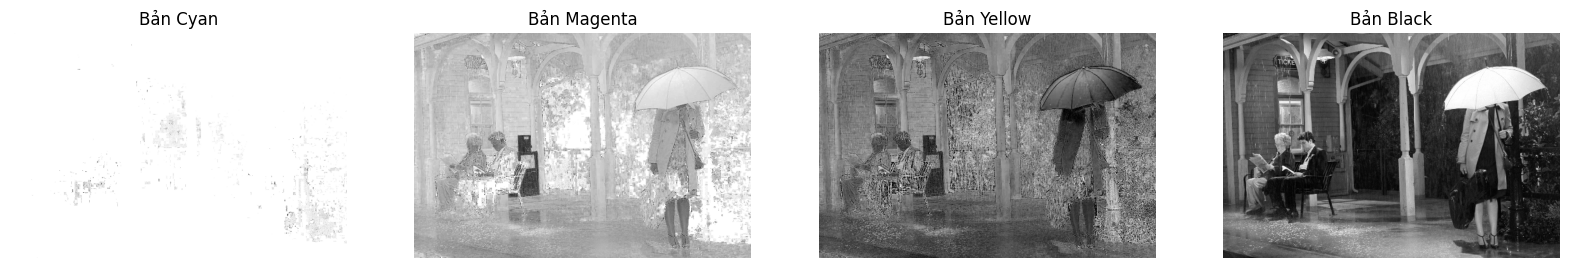

In [6]:
def rgb_to_cmyk(img):
    rgb = img.astype(np.float64) / 255.0
    K = 1 - rgb.max(axis=-1)
    cmy = np.divide(1 - rgb - K[..., None], (1 - K)[..., None],
                    out=np.zeros_like(rgb), where=(1 - K)[..., None] != 0)
    C, M, Y = np.moveaxis(cmy, -1, 0)
    return C, M, Y, K

C_, M_, Y_, K_ = rgb_to_cmyk(img)
check('Pixel trắng (255,255,255) có K = 0 và C=M=Y=0', lambda: np.allclose(np.array(rgb_to_cmyk(np.full((1, 1, 3), 255, np.uint8))).ravel(), 0))
check('Pixel đen (0,0,0) có K = 1', lambda: abs(rgb_to_cmyk(np.zeros((1, 1, 3), np.uint8))[3][0, 0] - 1) < 1e-9)
plates = [255 * (1 - p) for p in (C_, M_, Y_, K_)]
show(plates, ['Bản Cyan', 'Bản Magenta', 'Bản Yellow', 'Bản Black'], cmap='gray', figsize=(20, 4))

**Nhận xét**: Khi hiển thị bản mực, vùng càng tối tương ứng với lượng mực càng lớn. Cyan khá nhạt vì ảnh không có nhiều vùng cần thành phần này; Yellow thể hiện rõ tông vàng của cảnh. Black đậm ở các vùng thiếu sáng, giúp mô tả phần tối của ảnh.

## 3. Mô hình màu HSV và điều kiện chiếu sáng

HSV mô tả màu gần với cách con người cảm nhận: **H** (Hue – sắc độ, góc 0–360°), **S** (Saturation – độ bão hòa), **V** (Value – độ sáng). Trong OpenCV với ảnh uint8: H ∈ [0, 179] (= H/2), S, V ∈ [0, 255].

### 3.1. Chuyển một điểm ảnh RGB → HSV

Với `mx = max(R,G,B)`, `mn = min(R,G,B)` (R, G, B ∈ [0,1]), `d = mx − mn`:

- `V = mx`; `S = d / mx` (nếu `mx = 0` thì `S = 0`).
- `H = 0` nếu `d = 0`; `H = 60·((G − B)/d mod 6)` nếu `mx = R`; `H = 60·((B − R)/d + 2)` nếu `mx = G`; `H = 60·((R − G)/d + 4)` nếu `mx = B`.

**Yêu cầu**: viết hàm `rgb_to_hsv_pixel(r, g, b)` (đầu vào 0–255, trả về `H` độ trong [0, 360), `S`, `V` trong [0, 1]) và so sánh với `cv2.cvtColor`.

In [7]:
def rgb_to_hsv_pixel(r, g, b):
    r, g, b = r / 255.0, g / 255.0, b / 255.0
    mx, mn = max(r, g, b), min(r, g, b)
    d = mx - mn
    v = mx
    s = d / mx if mx else 0
    if d == 0:
        h = 0
    elif mx == r:
        h = 60 * (((g - b) / d) % 6)
    elif mx == g:
        h = 60 * ((b - r) / d + 2)
    else:
        h = 60 * ((r - g) / d + 4)
    return h, s, v

tests = [(200, 100, 50), (0, 255, 128), (255, 255, 0), (34, 139, 34), (128, 128, 128), (10, 20, 240)]
all_ok = True
for (r, g, b) in tests:
    h, s, v = rgb_to_hsv_pixel(r, g, b)
    cv_h, cv_s, cv_v = cv2.cvtColor(np.uint8([[[r, g, b]]]), cv2.COLOR_RGB2HSV)[0, 0]
    print((r, g, b), '->', f'H={h:6.1f}°  S={s:.2f}  V={v:.2f}   | OpenCV: H={cv_h * 2}°  S={cv_s / 255:.2f}  V={cv_v / 255:.2f}')
    all_ok &= abs(h - cv_h * 2) <= 2 and abs(s - cv_s / 255) < 0.01 and abs(v - cv_v / 255) < 0.01
check('rgb_to_hsv_pixel khớp OpenCV trên 6 màu mẫu', all_ok)

(200, 100, 50) -> H=  20.0°  S=0.75  V=0.78   | OpenCV: H=20°  S=0.75  V=0.78
(0, 255, 128) -> H= 150.1°  S=1.00  V=1.00   | OpenCV: H=150°  S=1.00  V=1.00
(255, 255, 0) -> H=  60.0°  S=1.00  V=1.00   | OpenCV: H=60°  S=1.00  V=1.00
(34, 139, 34) -> H= 120.0°  S=0.76  V=0.55   | OpenCV: H=120°  S=0.76  V=0.55
(128, 128, 128) -> H=   0.0°  S=0.00  V=0.50   | OpenCV: H=0°  S=0.00  V=0.50
(10, 20, 240) -> H= 237.4°  S=0.96  V=0.94   | OpenCV: H=238°  S=0.96  V=0.94
✔ Đúng: rgb_to_hsv_pixel khớp OpenCV trên 6 màu mẫu


### 3.2. Hiển thị các kênh H, S, V

**Yêu cầu**: chuyển ảnh `img` (RGB) sang HSV bằng `cv2.cvtColor`, tách thành 3 kênh `H, S, V` và hiển thị. Nhận xét: kênh nào mang thông tin về “màu”, kênh nào mang thông tin về “độ sáng”?

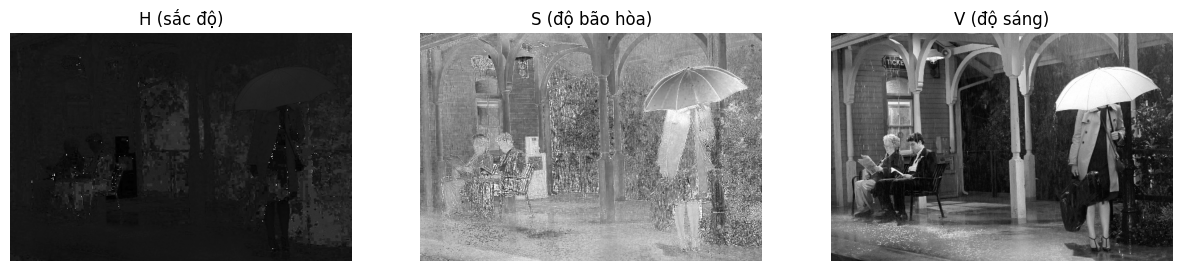

In [8]:
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
H, S, V = cv2.split(hsv)
show([H, S, V], ['H (sắc độ)', 'S (độ bão hòa)', 'V (độ sáng)'], cmap='gray', figsize=(15, 4))

**Nhận xét**: Kênh H mã hóa sắc độ nên độ sáng khi hiển thị kênh này không thể hiểu là độ sáng của cảnh. S mô tả mức bão hòa, còn V làm nổi bật chênh lệch sáng tối: chiếc ô sáng và các vùng nền tối nhìn rất rõ. Ba kênh cung cấp những thông tin khác nhau về cùng một ảnh.

### 3.3. Ảnh hưởng của điều kiện chiếu sáng lên các kênh màu

Thư mục `images/pieces` gồm các mảnh ảnh **cùng một màu** (vàng, xanh lam) cắt từ các ảnh khối Rubik chụp dưới 8 mức chiếu sáng khác nhau (`yellowr1…yellowr8`, `blue1r1…blue1r8`).

**Yêu cầu**: viết hàm `mean_channels(path, space)` trả về giá trị trung bình 3 kênh của ảnh theo không gian màu `space` (`'BGR'` hoặc `'HSV'`). Vẽ đồ thị giá trị trung bình từng kênh theo 8 ảnh cho hai màu và nhận xét: không gian nào ổn định hơn khi ánh sáng thay đổi?

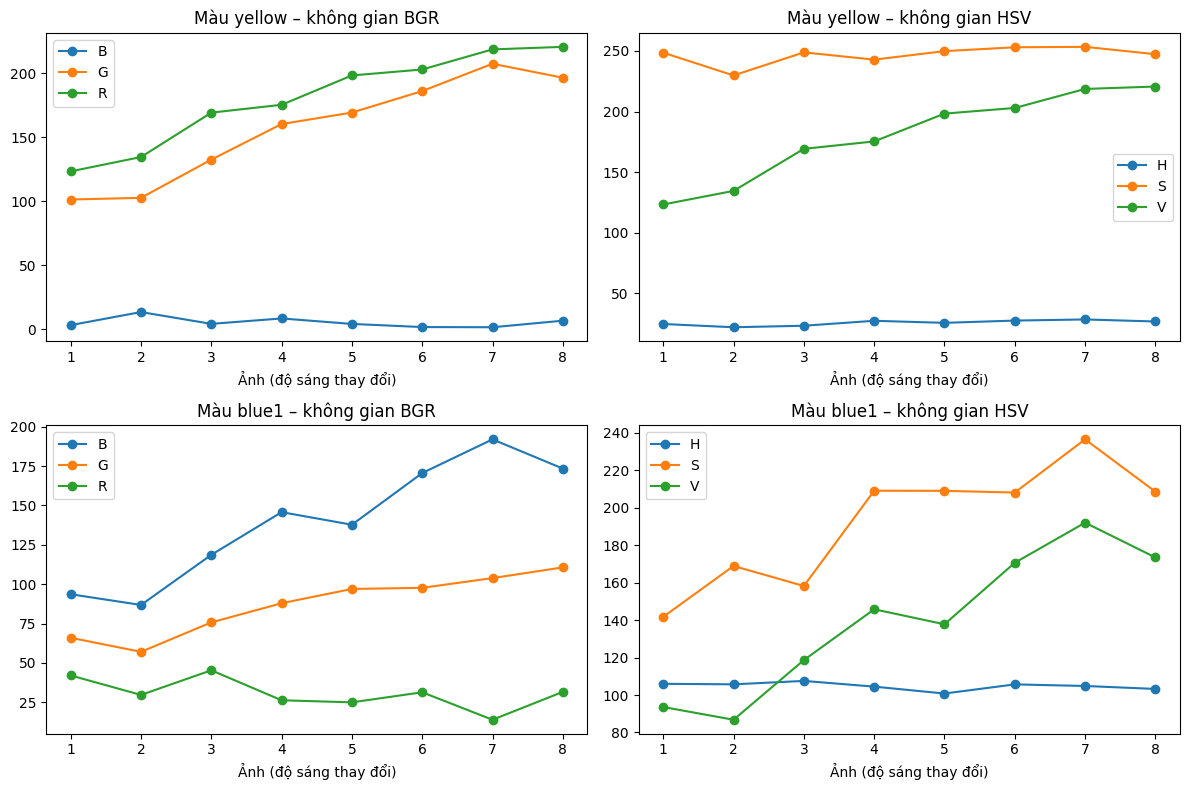

In [9]:
def mean_channels(path, space='BGR'):
    im = cv2.imread(path)
    if space == 'HSV':
        im = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    means = im.mean(axis=(0, 1))
    return means

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, color in enumerate(['yellow', 'blue1']):
    paths = [os.path.join(IMG_DIR, 'pieces', f'{color}r{k}.jpg') for k in range(1, 9)]
    for col, (space, labels) in enumerate([('BGR', 'BGR'), ('HSV', 'HSV')]):
        vals = np.array([mean_channels(p, space) for p in paths])
        for j, lab in enumerate(labels):
            axes[row, col].plot(range(1, 9), vals[:, j], marker='o', label=lab)
        axes[row, col].set_title(f'Màu {color} – không gian {space}')
        axes[row, col].set_xlabel('Ảnh (độ sáng thay đổi)')
        axes[row, col].legend()
plt.tight_layout()
plt.show()

**Nhận xét**: Ở màu vàng, H chỉ dao động khoảng 22,0–28,4 trong thang OpenCV, trong khi V thay đổi từ khoảng 123,3 đến 220,6. Với xanh lam, H cũng khá ổn định, khoảng 100,8–107,5, nhưng S và V biến động rõ. Kết quả cho thấy ưu điểm của việc tách sắc độ khỏi độ sáng trong HSV; tuy nhiên, không phải mọi kênh HSV đều ổn định trước thay đổi ánh sáng.

### 3.4. Phát hiện da người bằng ngưỡng trên không gian màu

Cho các ngưỡng (ảnh uint8 của OpenCV):

- HSV: `0 ≤ H ≤ 17`, `15 ≤ S ≤ 170`, `0 ≤ V ≤ 255`.
- YCrCb: `0 ≤ Y ≤ 255`, `135 ≤ Cr ≤ 180`, `85 ≤ Cb ≤ 135`.

**Yêu cầu**: viết hàm `skin_mask(img_bgr)` trả về 3 mặt nạ nhị phân (0/255): theo HSV, theo YCrCb và kết hợp (phép AND) cả hai. Thử với 3 ảnh `skin1.jpg, skin2.jpg, skin3.jpg` và nhận xét.

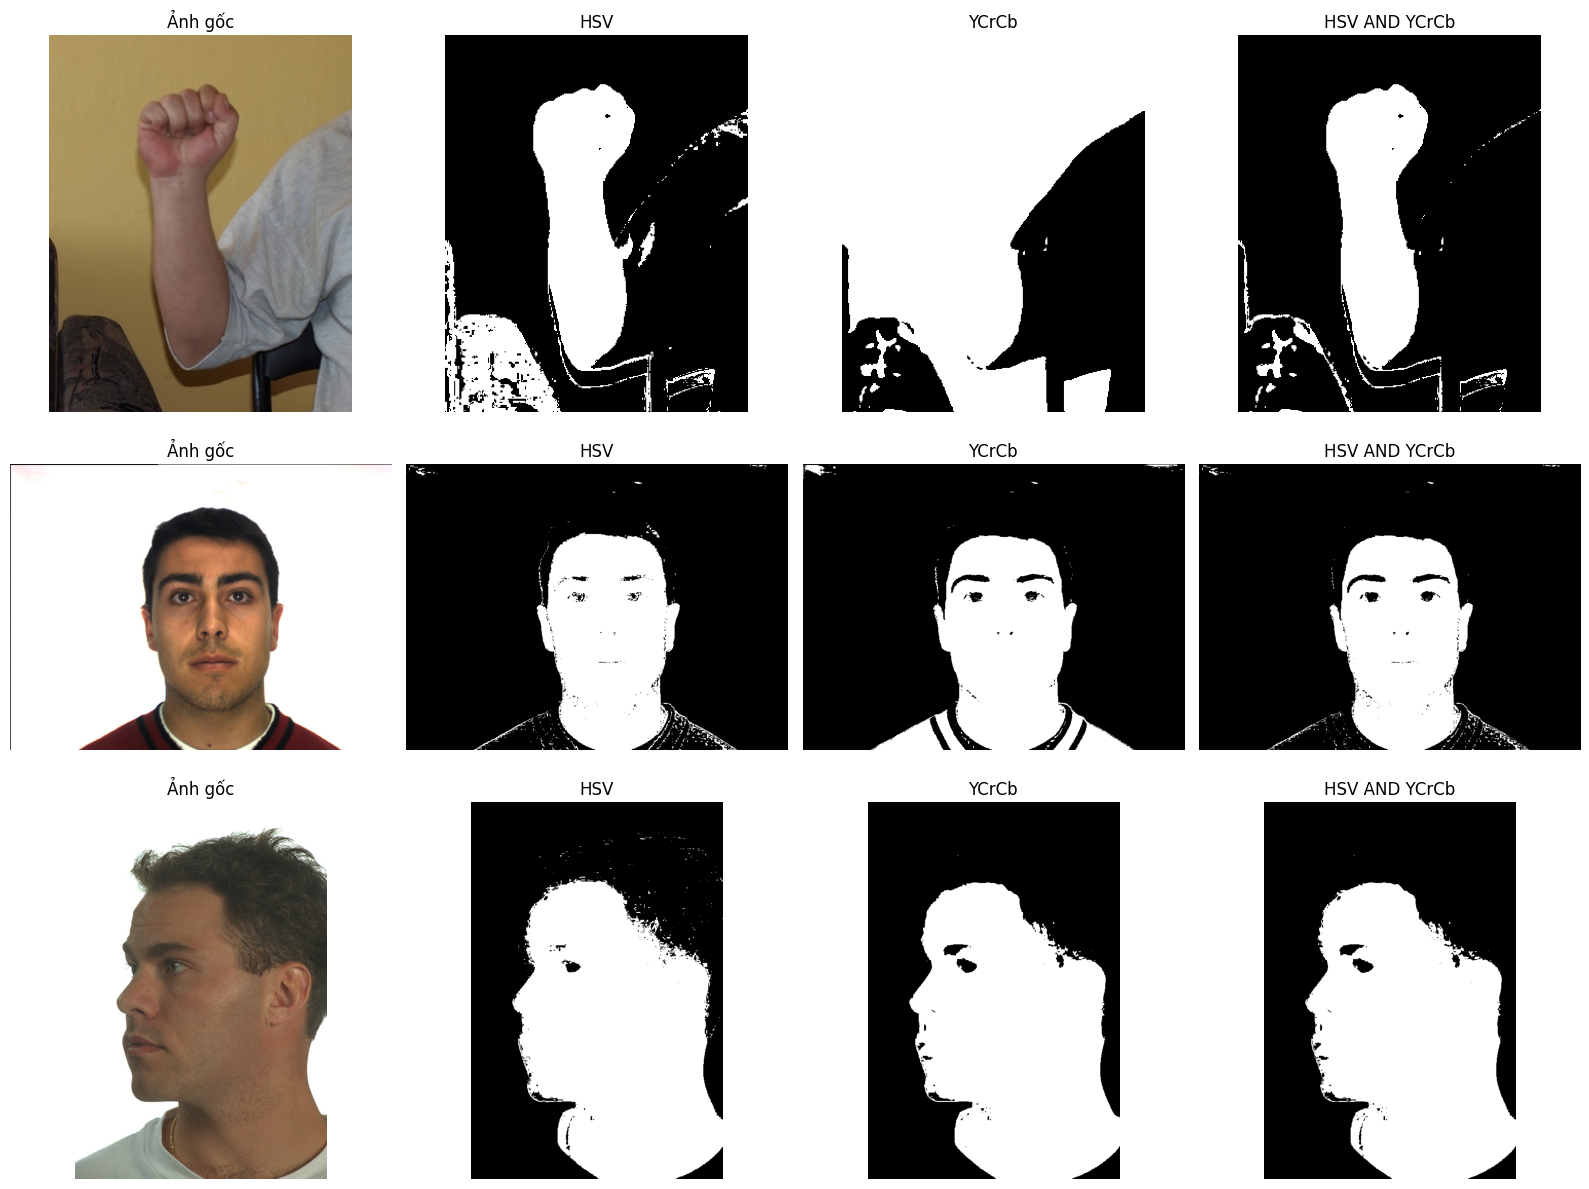

In [10]:
def skin_mask(img_bgr):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    ycc = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
    mask_hsv = cv2.inRange(hsv, (0, 15, 0), (17, 170, 255))
    mask_ycc = cv2.inRange(ycc, (0, 135, 85), (255, 180, 135))
    mask_both = cv2.bitwise_and(mask_hsv, mask_ycc)
    return mask_hsv, mask_ycc, mask_both

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i in range(3):
    im = cv2.imread(os.path.join(IMG_DIR, 'skin', f'skin{i + 1}.jpg'))
    mh, my, mb = skin_mask(im)
    for ax, data, title, cm in zip(axes[i], [cv2.cvtColor(im, cv2.COLOR_BGR2RGB), mh, my, mb],
                                   ['Ảnh gốc', 'HSV', 'YCrCb', 'HSV AND YCrCb'], [None, 'gray', 'gray', 'gray']):
        ax.imshow(data, cmap=cm); ax.set_title(title); ax.axis('off')
plt.tight_layout()
plt.show()

**Nhận xét**: Với ảnh 1, YCrCb chọn nhiều vùng nền có màu gần da. AND chỉ giữ phần cùng được cả hai cách chấp nhận nên giảm vùng nền bị chọn, nhưng đồng thời có thể loại những điểm da chỉ thỏa một bộ ngưỡng. Ở ảnh 2 và 3, vùng khuôn mặt được giữ khá tốt và hai mặt nạ gần nhau hơn. Chưa có mặt nạ chuẩn nên chỉ có thể đánh giá trực quan, chưa kết luận được độ chính xác bằng một tỷ lệ cụ thể.

## 4. Kỹ thuật in ảnh: tách ngưỡng, khuếch tán lỗi và halftone

Máy in chỉ có hai trạng thái “có mực / không mực” nên cần chuyển ảnh đa mức xám thành ảnh nhị phân (0 hoặc 255) mà vẫn **giữ được cảm nhận về độ sáng** của ảnh gốc.

### 4.1. Tách ngưỡng thông thường

**Yêu cầu**: viết hàm `simple_threshold(img, theta=127)` trả về ảnh nhị phân (0 nếu `img < theta`, ngược lại 255). Áp dụng cho ảnh xám `HoGuom.jpg`.

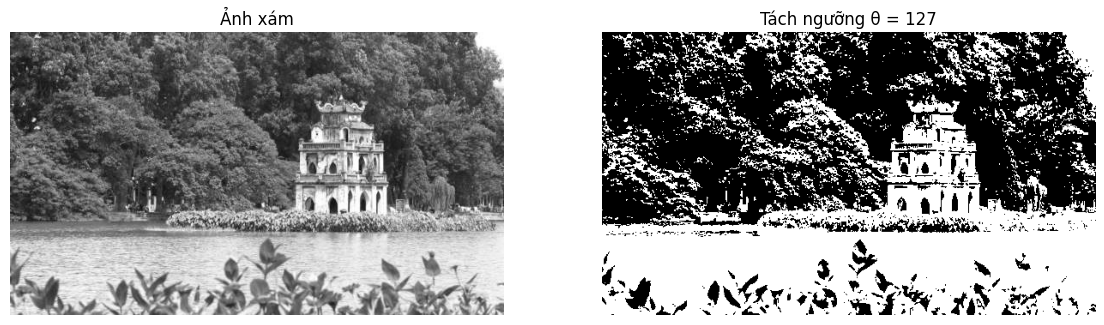

In [11]:
gray = cv2.imread(os.path.join(IMG_DIR, 'HoGuom.jpg'), cv2.IMREAD_GRAYSCALE)

def simple_threshold(img, theta=127):
    result = np.where(img < theta, 0, 255).astype(np.uint8)
    return result

thr = simple_threshold(gray)
show([gray, thr], ['Ảnh xám', 'Tách ngưỡng θ = 127'], cmap='gray', figsize=(14, 5))

### 4.2. Khuếch tán lỗi một chiều

Quy trình (quét từng dòng, từ trái sang phải; sai số chỉ chuyển sang điểm kế tiếp **trên cùng dòng**, hết dòng thì bỏ):

- `e = 0` ở đầu mỗi dòng.
- `u = I[i, j] − e`
- `b = 0` nếu `u < θ`, ngược lại `b = 255`
- `e = b − u` (sai số lượng tử hóa, chuyển cho điểm kế tiếp)

**Yêu cầu**: viết hàm `error_diffusion_1d(img, theta=127)` trả về ảnh nhị phân 0/255 (kiểu `uint8`). Hãy dùng biến `int` hoặc `float` để tính `u` (tránh tràn số `uint8`). Kiểm tra với Câu 4.T2, 4.T4 trong bài tập tính tay.

In [12]:
def error_diffusion_1d(img, theta=127):
    h, w = img.shape
    out = np.zeros((h, w), dtype=np.uint8)
    for i in range(h):
        e = 0.0
        for j in range(w):
            u = float(img[i, j]) - e
            b = 0 if u < theta else 255
            out[i, j] = b
            e = b - u
    return out

ex_4_t2 = np.array([[20, 200, 90, 140, 60], [250, 35, 180, 70, 120], [15, 100, 230, 45, 160]], dtype=np.uint8)
ex_4_t2_ans = np.array([[0, 255, 0, 255, 0], [255, 0, 255, 0, 255], [0, 0, 255, 255, 0]], dtype=np.uint8)
ex_4_t4 = np.array([[130, 125, 128, 40, 200], [90, 90, 90, 90, 90], [210, 15, 177, 63, 142]], dtype=np.uint8)
ex_4_t4_ans = np.array([[255, 0, 255, 0, 255], [0, 255, 0, 255, 0], [255, 0, 255, 0, 0]], dtype=np.uint8)

check('Câu 4.T2 (θ = 127)', lambda: np.array_equal(error_diffusion_1d(ex_4_t2, 127), ex_4_t2_ans))
check('Câu 4.T4 (θ = 100)', lambda: np.array_equal(error_diffusion_1d(ex_4_t4, 100), ex_4_t4_ans))
print(error_diffusion_1d(ex_4_t2, 127))

✔ Đúng: Câu 4.T2 (θ = 127)
✔ Đúng: Câu 4.T4 (θ = 100)
[[  0 255   0 255   0]
 [255   0 255   0 255]
 [  0   0 255 255   0]]


### 4.3. So sánh tách ngưỡng và khuếch tán lỗi trên ảnh thật

**Yêu cầu**: áp dụng `error_diffusion_1d` cho ảnh `HoGuom.jpg`, hiển thị kết quả cạnh ảnh tách ngưỡng ở 4.1 và **phóng to** một vùng 80×80 điểm ảnh (dùng `cv2.resize(..., interpolation=cv2.INTER_NEAREST)`). Tính độ sáng trung bình của ba ảnh (ảnh gốc, tách ngưỡng, khuếch tán lỗi) và nhận xét ảnh nào giữ độ sáng trung bình gần ảnh gốc hơn.

Độ sáng trung bình: ảnh gốc = 135.8, tách ngưỡng = 120.4, khuếch tán lỗi = 135.8
✔ Đúng: Khuếch tán lỗi giữ độ sáng trung bình gần ảnh gốc hơn


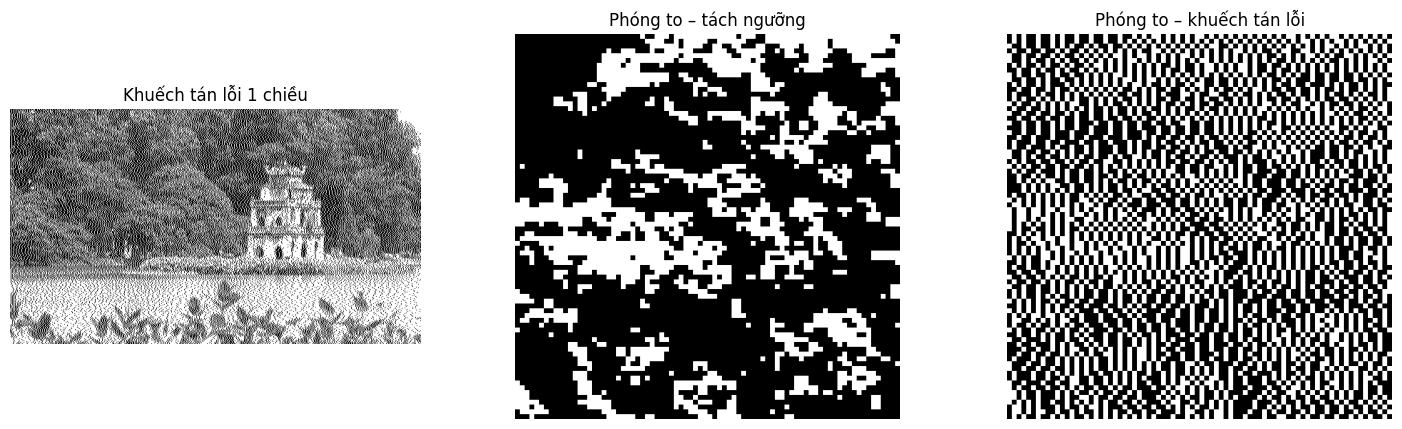

In [13]:
ed1 = error_diffusion_1d(gray)
mean_gray, mean_thr, mean_ed = gray.mean(), thr.mean(), ed1.mean()
print(f'Độ sáng trung bình: ảnh gốc = {mean_gray:.1f}, tách ngưỡng = {mean_thr:.1f}, khuếch tán lỗi = {mean_ed:.1f}')
check('Khuếch tán lỗi giữ độ sáng trung bình gần ảnh gốc hơn', lambda: abs(mean_ed - mean_gray) < abs(mean_thr - mean_gray))
crop = lambda a: cv2.resize(a[100:180, 200:280], None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)
show([ed1, crop(thr), crop(ed1)], ['Khuếch tán lỗi 1 chiều', 'Phóng to – tách ngưỡng', 'Phóng to – khuếch tán lỗi'], cmap='gray', figsize=(18, 5))

**Nhận xét**: Tách ngưỡng biến các vùng xám thành mảng đen hoặc trắng lớn, khiến ảnh mất sắc độ trung gian. Khuếch tán lỗi chuyển sai số sang điểm kế tiếp, tạo mật độ chấm phù hợp hơn với độ sáng ban đầu. Giá trị trung bình làm tròn của ảnh gốc và ảnh khuếch tán đều là 135,8, trong khi tách ngưỡng là 120,4. Tuy vậy, vùng phóng to cho thấy hướng quét một chiều để lại các vệt rõ.

### 4.4. Khuếch tán lỗi hai chiều – Floyd–Steinberg (mở rộng)

Khuếch tán lỗi hai chiều chia sai số `e` cho cả các điểm lân cận phía dưới. Với Floyd–Steinberg, sau khi lượng tử hóa điểm `(i, j)`, sai số được cộng vào:

- `(i, j+1)`: `7/16·e`  
- `(i+1, j−1)`: `3/16·e`  
- `(i+1, j)`: `5/16·e`  
- `(i+1, j+1)`: `1/16·e`

**Yêu cầu**: viết hàm `floyd_steinberg(img, theta=127)` (làm việc trên bản sao kiểu `float`, ở đây `e = u − b` với `u` là giá trị hiện tại của điểm ảnh, `b` là 0 hoặc 255) và so sánh với khuếch tán lỗi một chiều.

Độ sáng trung bình Floyd–Steinberg: 135.8 | ảnh gốc: 135.8
✔ Đúng: Floyd–Steinberg giữ độ sáng trung bình (sai lệch < 5)


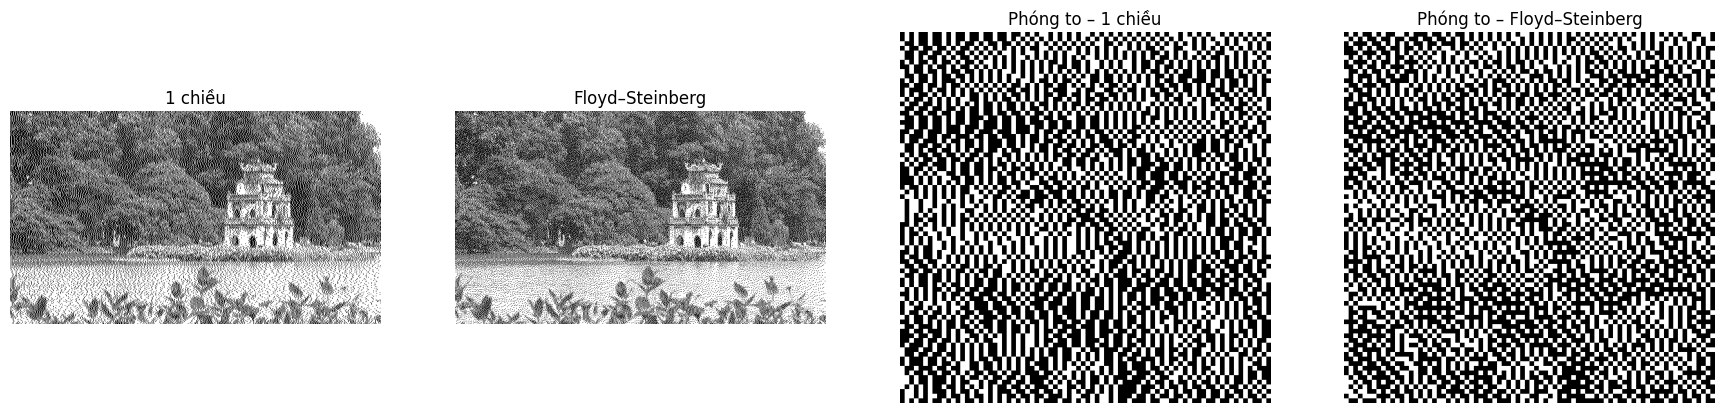

In [14]:
def floyd_steinberg(img, theta=127):
    f = img.astype(np.float64).copy()
    h, w = f.shape
    out = np.zeros((h, w), dtype=np.uint8)
    for i in range(h):
        for j in range(w):
            u = f[i, j]
            b = 0 if u < theta else 255
            out[i, j] = b
            e = u - b
            if j + 1 < w:
                f[i, j + 1] += e * 7 / 16
            if i + 1 < h:
                if j > 0:
                    f[i + 1, j - 1] += e * 3 / 16
                f[i + 1, j] += e * 5 / 16
                if j + 1 < w:
                    f[i + 1, j + 1] += e / 16
    return out

fs = floyd_steinberg(gray)
print('Độ sáng trung bình Floyd–Steinberg:', round(fs.mean(), 1), '| ảnh gốc:', round(gray.mean(), 1))
check('Floyd–Steinberg giữ độ sáng trung bình (sai lệch < 5)', lambda: abs(fs.mean() - gray.mean()) < 5)
show([ed1, fs, crop(ed1), crop(fs)], ['1 chiều', 'Floyd–Steinberg', 'Phóng to – 1 chiều', 'Phóng to – Floyd–Steinberg'], cmap='gray', figsize=(22, 5))

**Nhận xét**: Floyd–Steinberg chia sai số cho điểm bên phải và ba điểm ở dòng dưới, nhờ đó giảm dấu vết của hướng quét so với cách một chiều. Quan sát vùng phóng to, các chấm phân bố đa hướng hơn. Độ sáng trung bình vẫn khoảng 135,8, nhưng giá trị trung bình gần nhau không có nghĩa cấu trúc chấm của hai ảnh giống nhau.

### 4.5. Halftone bằng ma trận ngưỡng (ordered dithering)

Một cách mô phỏng halftone là so sánh từng điểm ảnh với một **ma trận ngưỡng** lặp lại theo từng khối. Với ma trận Bayer 4×4:

```
 0   8   2  10
12   4  14   6
 3  11   1   9
15   7  13   5
```

ngưỡng tại vị trí `(i, j)` là `T(i, j) = (B[i mod 4, j mod 4] + 0.5) / 16 · 255`; điểm ảnh là trắng nếu `img ≥ T(i, j)`.

**Yêu cầu**: viết hàm `ordered_dither(img)` và so sánh với hai phương pháp trên.

Độ sáng trung bình ordered dithering: 135.8 | ảnh gốc: 135.8


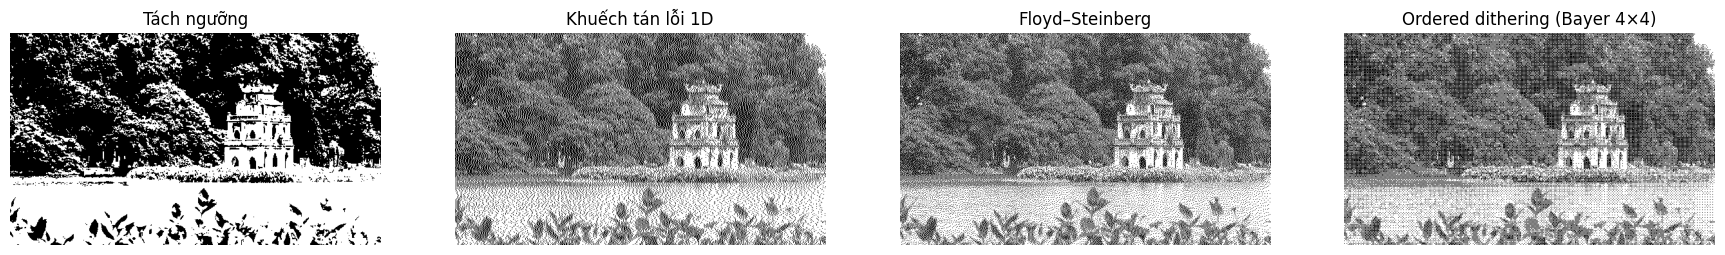

In [15]:
BAYER4 = np.array([[0, 8, 2, 10], [12, 4, 14, 6], [3, 11, 1, 9], [15, 7, 13, 5]])

def ordered_dither(img):
    h, w = img.shape
    thresholds = (BAYER4[np.arange(h)[:, None] % 4, np.arange(w) % 4] + 0.5) * 255 / 16
    out = np.where(img >= thresholds, 255, 0).astype(np.uint8)
    return out

od = ordered_dither(gray)
print('Độ sáng trung bình ordered dithering:', round(od.mean(), 1), '| ảnh gốc:', round(gray.mean(), 1))
show([thr, ed1, fs, od], ['Tách ngưỡng', 'Khuếch tán lỗi 1D', 'Floyd–Steinberg', 'Ordered dithering (Bayer 4×4)'], cmap='gray', figsize=(22, 5))

**Nhận xét**: Ba phương pháp dithering đều tái hiện mức xám bằng mật độ điểm đen trắng, nên giữ cảm giác sáng tối tốt hơn tách ngưỡng. Bayer dùng ma trận 4×4 lặp lại nên xuất hiện hoa văn có quy luật, còn khuếch tán lỗi tạo mẫu phụ thuộc vào nội dung ảnh. Bayer đạt độ sáng trung bình khoảng 135,8; về cảm nhận hình ảnh, Floyd–Steinberg có mẫu chấm ít đều đặn hơn.

## 5. Mô hình raster và mô hình vector

Ảnh **raster** là ma trận điểm ảnh nên khi phóng to sẽ bị vỡ hạt; ảnh **vector** lưu công thức hình học (tọa độ, bán kính…) nên vẽ lại sắc nét ở mọi kích thước.

**Yêu cầu**: tạo ảnh raster 40×40 chứa một hình tròn bán kính 15 (dùng `cv2.circle`), phóng to 10 lần bằng hai cách nội suy `INTER_NEAREST` và `INTER_CUBIC`; so sánh với hình tròn vẽ bằng `matplotlib.patches.Circle` (vector) ở cùng kích thước 400×400. Nhận xét.

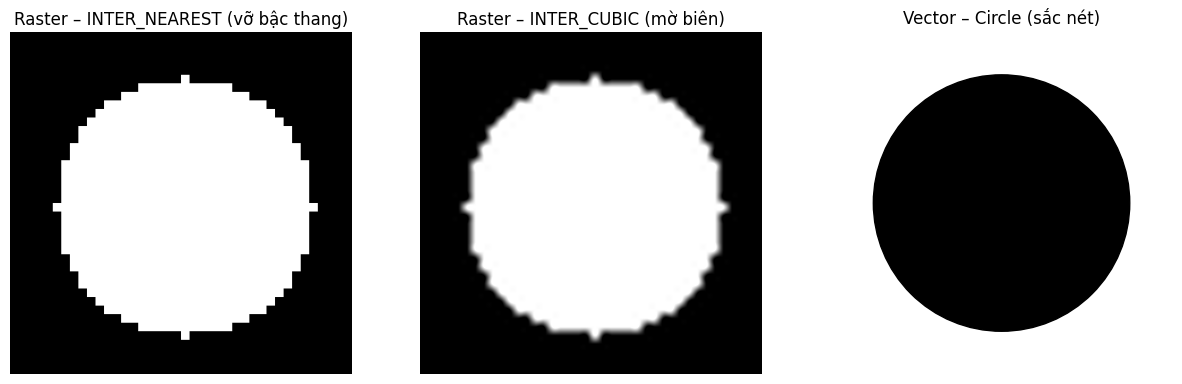

In [16]:
import matplotlib.patches as patches

small = np.zeros((40, 40), dtype=np.uint8)
cv2.circle(small, (20, 20), 15, 255, -1)
zoom_nearest = cv2.resize(small, (400, 400), interpolation=cv2.INTER_NEAREST)
zoom_cubic = cv2.resize(small, (400, 400), interpolation=cv2.INTER_CUBIC)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(zoom_nearest, cmap='gray'); axes[0].set_title('Raster – INTER_NEAREST (vỡ bậc thang)')
axes[1].imshow(zoom_cubic, cmap='gray'); axes[1].set_title('Raster – INTER_CUBIC (mờ biên)')
axes[2].add_patch(patches.Circle((200, 200), 150, color='k')); axes[2].set_xlim(0, 400); axes[2].set_ylim(400, 0)
axes[2].set_aspect('equal'); axes[2].set_title('Vector – Circle (sắc nét)')
for ax in axes: ax.axis('off')
plt.show()

**Nhận xét**: Từ ảnh raster 40×40, nearest phóng các điểm ảnh thành ô lớn nên viền tròn hiện rõ bậc thang. Cubic nội suy thêm mức xám ở biên, giúp chuyển tiếp mềm hơn nhưng không khôi phục được chi tiết đã thiếu trong ảnh nhỏ. Hình tròn vector được dựng lại theo tâm và bán kính tại kích thước mới nên có đường biên mượt, rõ hơn.

## 6. Bài tập tổng hợp: mô phỏng quy trình in ảnh màu CMYK

Máy in màu tạo ảnh bằng 4 **bản mực** C, M, Y, K; mỗi bản là ảnh nhị phân (có mực / không mực) sinh bằng kỹ thuật nửa cường độ. Hãy mô phỏng quy trình này cho ảnh `himym.jpg` (đã thu nhỏ):

1. Tách ảnh thành 4 bản mực `C, M, Y, K` bằng `rgb_to_cmyk`; nhân với 255 để có ảnh mật độ mực thang 0–255 (giá trị lớn = nhiều mực).
2. Lượng tử hóa mỗi bản bằng kỹ thuật nửa cường độ (ví dụ `floyd_steinberg`) để có ảnh nhị phân (255 = có mực).
3. Ghép lại: `R = 255·(1 − C)(1 − K)`, `G = 255·(1 − M)(1 − K)`, `B = 255·(1 − Y)(1 − K)` với C, M, Y, K ∈ {0, 1}.
4. So sánh kết quả với ảnh gốc theo cách **mắt người nhìn từ xa**: làm mờ cả hai ảnh bằng `cv2.GaussianBlur(..., (9, 9), 0)` rồi tính sai số trung bình tuyệt đối (MAE); so sánh phương án dùng `floyd_steinberg` với phương án dùng `simple_threshold` cho từng bản mực. (So sánh từng điểm ảnh sẽ không công bằng cho halftone vì halftone chỉ giữ đúng độ sáng trung bình cục bộ.)

**Yêu cầu**: viết hàm `print_simulation(img, halftone)` với tham số `halftone` là hàm lượng tử hóa (nhận ảnh 0–255 và trả về ảnh 0/255).

MAE (sau làm mờ) so với ảnh gốc: Floyd–Steinberg = 6.6, tách ngưỡng = 44.7
✔ Đúng: Halftone bằng Floyd–Steinberg gần ảnh gốc hơn tách ngưỡng (khi nhìn từ xa)


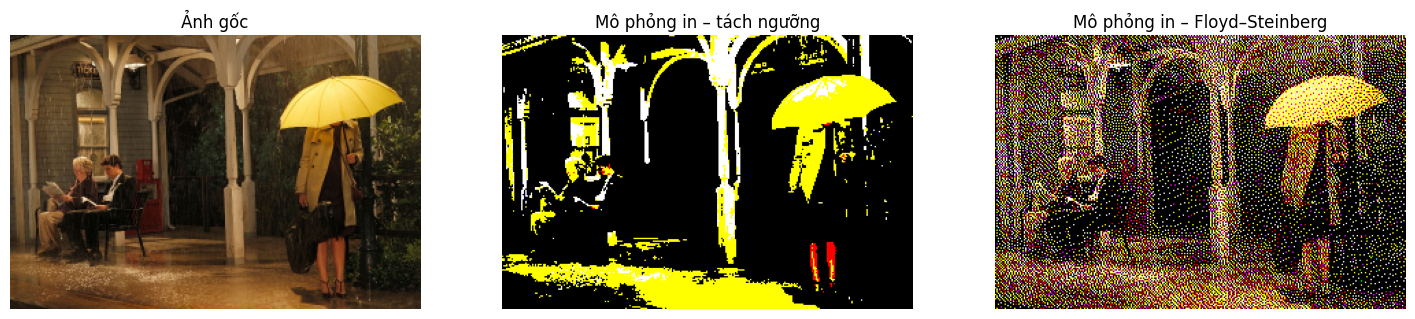

In [17]:
def print_simulation(img, halftone):
    C, M, Y, K = rgb_to_cmyk(img)
    C, M, Y, K = [halftone(p * 255).astype(float) / 255 for p in (C, M, Y, K)]
    result = np.stack([(1 - C) * (1 - K), (1 - M) * (1 - K),
                       (1 - Y) * (1 - K)], axis=-1)
    result = np.round(result * 255).astype(np.uint8)
    return result

small_img = cv2.resize(img, (300, 200))
sim_fs = print_simulation(small_img, lambda p: floyd_steinberg(p, 127))
sim_thr = print_simulation(small_img, lambda p: simple_threshold(p, 127))
blur = lambda a: cv2.GaussianBlur(a, (9, 9), 0).astype(float)
mae = lambda a: np.abs(blur(a) - blur(small_img)).mean()
print(f'MAE (sau làm mờ) so với ảnh gốc: Floyd–Steinberg = {mae(sim_fs):.1f}, tách ngưỡng = {mae(sim_thr):.1f}')
check('Halftone bằng Floyd–Steinberg gần ảnh gốc hơn tách ngưỡng (khi nhìn từ xa)', lambda: mae(sim_fs) < mae(sim_thr))
show([small_img, sim_thr, sim_fs], ['Ảnh gốc', 'Mô phỏng in – tách ngưỡng', 'Mô phỏng in – Floyd–Steinberg'], figsize=(18, 4))

**Nhận xét**: Khi nhị phân hóa từng bản mực bằng tách ngưỡng, nhiều vùng màu trung gian bị mất và ảnh xuất hiện các mảng màu gắt. Floyd–Steinberg dùng mật độ chấm để mô phỏng lượng mực nên giữ màu tổng thể tốt hơn khi nhìn xa. Sau GaussianBlur 9×9, MAE giảm từ 44,7 xuống 6,6, tức khoảng 6,8 lần. Kết quả này đánh giá mức gần nhau sau làm mờ, không khẳng định từng điểm ảnh của bản in trùng ảnh gốc.